In [1]:
import pandas as pd
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [10]:
data = pd.read_csv("Churn_Modelling.csv")

In [11]:
print(tf.version)

<module 'tensorflow._api.v2.version' from '/Users/akhilesh/DL_LEARNINGS/tensorflow-learning/tensorflowVENV/lib/python3.11/site-packages/tensorflow/_api/v2/version/__init__.py'>


In [12]:
data

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [13]:
data= data.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)
data.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [14]:
X= data
y= data.iloc[:,10]

In [15]:
y

0       1
1       0
2       1
3       0
4       0
       ..
9995    0
9996    0
9997    1
9998    1
9999    0
Name: Exited, Length: 10000, dtype: int64

In [16]:
X.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [17]:
geography=pd.get_dummies(X['Geography'], drop_first=True)
gender = pd.get_dummies(X['Gender'], drop_first=True)

In [18]:
X=X.drop(['Geography', 'Gender'],axis=1)

In [19]:
X.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,42,2,0.00,1,1,1,101348.88,1
1,608,41,1,83807.86,1,0,1,112542.58,0
2,502,42,8,159660.80,3,1,0,113931.57,1
3,699,39,1,0.00,2,0,0,93826.63,0
4,850,43,2,125510.82,1,1,1,79084.10,0


In [20]:
X=pd.concat([X, geography, gender], axis=1)

In [21]:
X

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Germany,Spain,Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,0,False,False,True
9996,516,35,10,57369.61,1,1,1,101699.77,0,False,False,True
9997,709,36,7,0.00,1,0,1,42085.58,1,False,False,False
9998,772,42,3,75075.31,2,1,0,92888.52,1,True,False,True


In [22]:
from sklearn.model_selection import train_test_split

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [24]:
from sklearn.preprocessing import StandardScaler

In [25]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [26]:
X_train.shape,y_train.shape

((8000, 12), (8000,))

In [27]:
X_train

array([[ 0.16958176, -0.46460796,  0.00666099, ..., -0.5698444 ,
         1.74309049, -1.09168714],
       [-2.30455945,  0.30102557, -1.37744033, ...,  1.75486502,
        -0.57369368,  0.91601335],
       [-1.19119591, -0.94312892, -1.031415  , ..., -0.5698444 ,
        -0.57369368, -1.09168714],
       ...,
       [ 0.9015152 , -0.36890377,  0.00666099, ..., -0.5698444 ,
        -0.57369368,  0.91601335],
       [-0.62420521, -0.08179119,  1.39076231, ..., -0.5698444 ,
         1.74309049, -1.09168714],
       [-0.28401079,  0.87525072, -1.37744033, ...,  1.75486502,
        -0.57369368, -1.09168714]], shape=(8000, 12))

In [28]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LeakyReLU,PReLU,ELU,ReLU
from tensorflow.keras.layers import Dropout

In [29]:
classifier = Sequential()

## Adding the input layer and the first hidden layer


In [30]:
classifier.add(Dense(units=11, activation='relu'))

In [31]:
classifier.add(Dense(units=7, activation='relu'))

In [32]:
classifier.add(Dense(units=6, activation='relu'))

In [33]:
classifier.add(Dense(units=1, activation='sigmoid'))

In [34]:
import tensorflow 
opt = tensorflow.keras.optimizers.Adam(learning_rate=0.01)

In [35]:
classifier.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])

In [36]:
earlystopping = tensorflow.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    min_delta=0.0001,
    patience=10,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False,
    start_from_epoch=0,
)


In [37]:
model_history= classifier.fit(X_train, y_train,validation_split=0.33,batch_size=10, epochs=100,callbacks=[earlystopping])

Epoch 1/100
536/536 ━━━━━━━━━━━━━━━━━━━━ 1s 532us/step - accuracy: 0.9761 - loss: 0.0509 - val_accuracy: 1.0000 - val_loss: 2.9166e-05
Epoch 2/100
536/536 ━━━━━━━━━━━━━━━━━━━━ 0s 414us/step - accuracy: 1.0000 - loss: 1.4511e-05 - val_accuracy: 1.0000 - val_loss: 7.1430e-06
Epoch 3/100
536/536 ━━━━━━━━━━━━━━━━━━━━ 0s 412us/step - accuracy: 1.0000 - loss: 4.9234e-06 - val_accuracy: 1.0000 - val_loss: 3.1715e-06
Epoch 4/100
536/536 ━━━━━━━━━━━━━━━━━━━━ 0s 412us/step - accuracy: 1.0000 - loss: 2.4349e-06 - val_accuracy: 1.0000 - val_loss: 1.6851e-06
Epoch 5/100
536/536 ━━━━━━━━━━━━━━━━━━━━ 0s 421us/step - accuracy: 1.0000 - loss: 1.4016e-06 - val_accuracy: 1.0000 - val_loss: 1.0082e-06
Epoch 6/100
536/536 ━━━━━━━━━━━━━━━━━━━━ 0s 413us/step - accuracy: 1.0000 - loss: 8.7216e-07 - val_accuracy: 1.0000 - val_loss: 6.4055e-07
Epoch 7/100
536/536 ━━━━━━━━━━━━━━━━━━━━ 0s 410us/step - accuracy: 1.0000 - loss: 5.7003e-07 - val_accuracy: 1.0000 - val_loss: 4.2927e-07
Epoch 8/100
536/536 ━━━━━━━━━━━

In [38]:
model_history

In [39]:
model_history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

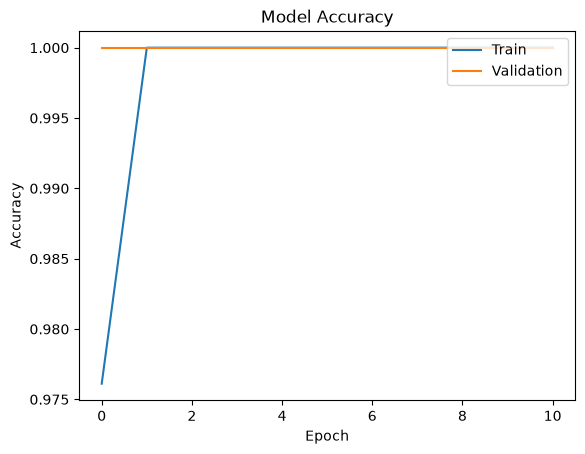

In [40]:
plt.plot(model_history.history['accuracy'])
plt.plot(model_history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()